<center><h1>Liang_Jean_HW4</h1></center>
<br>
<br>

Name: Jean Liang
<br>
Github Username: jeanliang05
<br>
USC ID: 5919931306

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.feature_selection import RFECV, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [8]:
data_dir = Path("AReM")
csv_files = sorted(data_dir.rglob("*.csv"))

print(len(csv_files))

88


### (b) Splitting Data

In [10]:
test_files = []
train_files = []

for file in csv_files:
    activity = file.parent.name.lower()
    dataset_num = int(file.stem.replace("dataset", ""))

    test_max = 2 if activity in {"bending1", "bending2"} else 3

    if dataset_num <= test_max:
        test_files.append(file)
    else:
        train_files.append(file)

print("Training files:", len(train_files))
print("Test files:", len(test_files))

Training files: 69
Test files: 19


### (c) Feature Extraction

In [12]:
columns = [
    "time", "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
]
sensor_columns = columns[1:]

def extract_features(file):
    rows = []

    for line_number, line in enumerate(file.read_text().splitlines()[5:], start=6):
        values = line.replace(",", " ").split()

        if not values:
            continue

        if len(values) != 7:
            raise ValueError(
                f"{file}, line {line_number}: expected 7 values, found {len(values)}"
            )

        rows.append(values)

    data = pd.DataFrame(rows, columns=columns, dtype=float)
    row = {}

    for col in sensor_columns:
        s = data[col]
        row[f"{col}_min"] = s.min()
        row[f"{col}_max"] = s.max()
        row[f"{col}_mean"] = s.mean()
        row[f"{col}_median"] = s.median()
        row[f"{col}_std"] = s.std()
        row[f"{col}_first_quartile"] = s.quantile(0.25)
        row[f"{col}_third_quartile"] = s.quantile(0.75)

    row["activity"] = (
        "bending" if file.parent.name.lower().startswith("bending")
        else file.parent.name.lower()
    )
    row["file"] = str(file.relative_to(data_dir))
    return row

features_df = pd.DataFrame([extract_features(file) for file in csv_files])
features_df.head()

,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_first_quartile,avg_rss12_third_quartile,var_rss12_min,var_rss12_max,var_rss12_mean,...,avg_rss23_third_quartile,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_first_quartile,var_rss23_third_quartile,activity,file
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30,bending,bending1/dataset1.csv
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30,bending,bending1/dataset2.csv
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94,bending,bending1/dataset3.csv
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00,bending,bending1/dataset4.csv
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50,bending,bending1/dataset5.csv


In [13]:
feature_cols = [
    col for col in features_df.columns
    if col not in ["activity", "file"]
]

values = features_df[feature_cols].to_numpy()
estimated_sds = np.std(values, axis=0, ddof=1)

rng = np.random.default_rng(1)
bootstrap_sds = np.empty((1000, len(feature_cols)))

for b in range(1000):
    indices = rng.integers(0, len(values), size=len(values))
    bootstrap_sds[b] = np.std(values[indices], axis=0, ddof=1)

ci_lower, ci_upper = np.percentile(bootstrap_sds, [5, 95], axis=0)

std_results = pd.DataFrame({
    "Feature": feature_cols,
    "Estimated SD": estimated_sds,
    "90% CI lower": ci_lower,
    "90% CI upper": ci_upper
})

std_results

,Feature,Estimated SD,90% CI lower,90% CI upper
0,avg_rss12_min,9.569975,8.278846,10.908792
1,avg_rss12_max,4.394362,3.287317,5.292062
2,avg_rss12_mean,5.335718,4.701487,5.889290
3,avg_rss12_median,5.440054,4.796361,6.023666
4,avg_rss12_std,1.772153,1.571117,1.948094
5,avg_rss12_first_quartile,6.153590,5.579874,6.662732
6,avg_rss12_third_quartile,5.138925,4.313154,5.826573
7,var_rss12_min,0.000000,0.000000,0.000000
8,var_rss12_max,5.062729,4.610176,5.402727
9,var_rss12_mean,1.574164,1.397591,1.708244


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

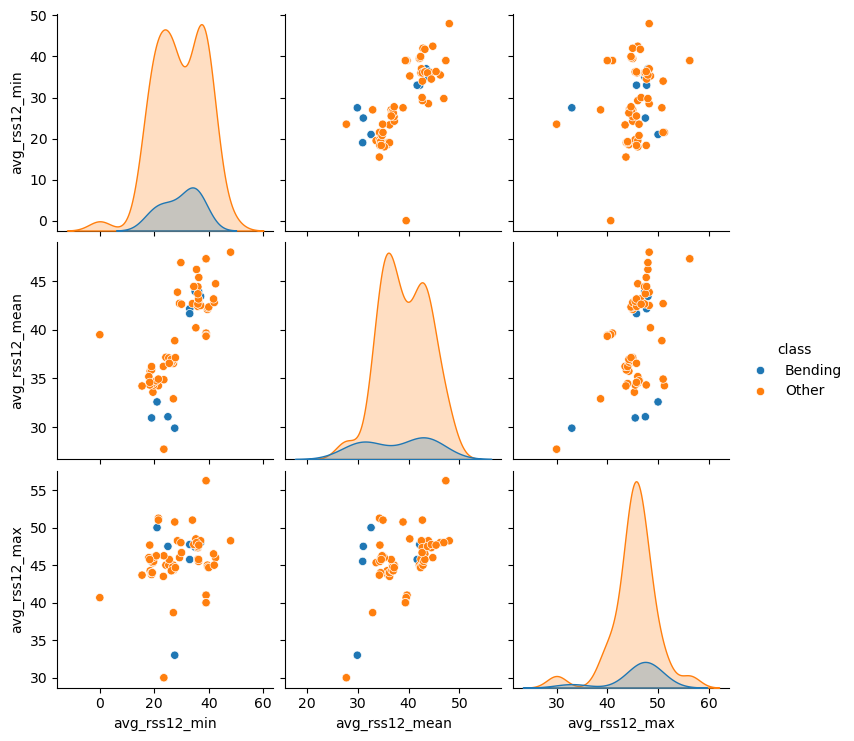

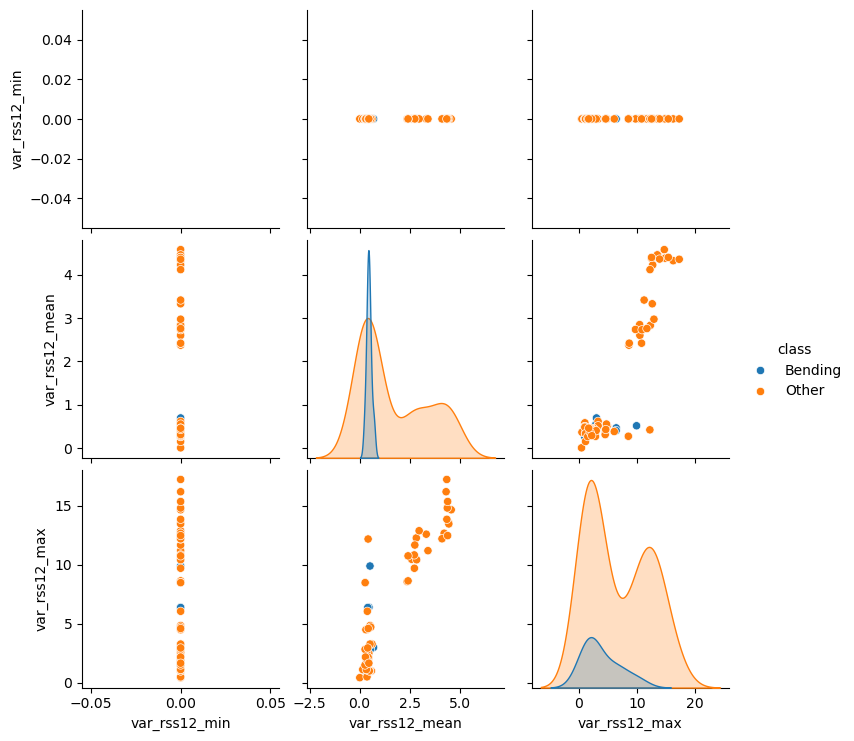

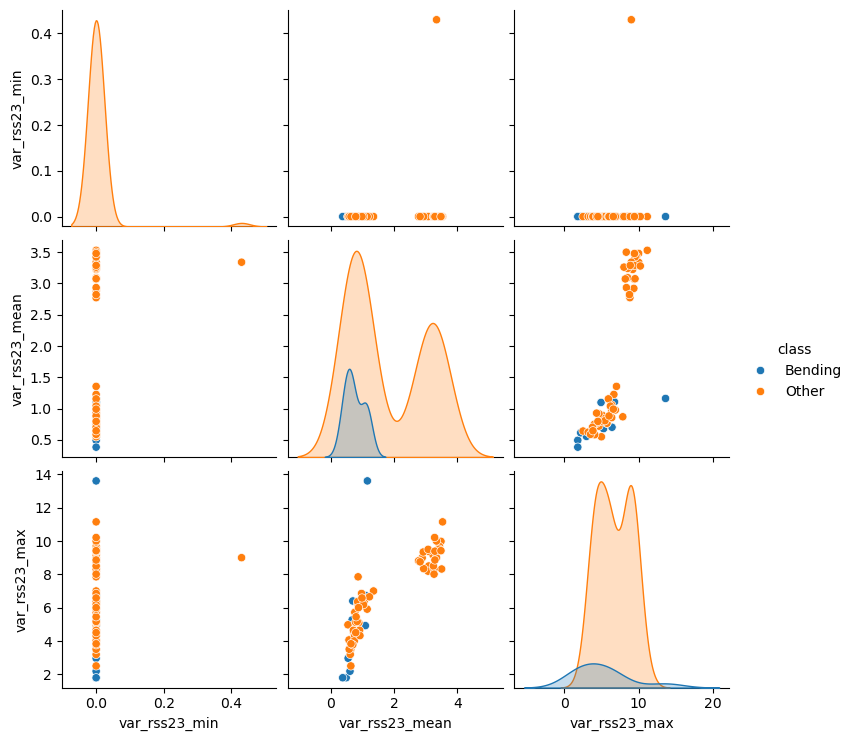

In [17]:
train_names = {str(f.relative_to(data_dir)) for f in train_files}
train_df = features_df[features_df["file"].isin(train_names)].copy()
train_df["class"] = train_df["activity"].str.startswith("bending").map(
    {True: "Bending", False: "Other"}
)

for sensor in ["avg_rss12", "var_rss12", "var_rss23"]:
    sns.pairplot(
        train_df,
        vars=[f"{sensor}_min", f"{sensor}_mean", f"{sensor}_max"],
        hue="class"
    )

#### ii. Splitted Plots

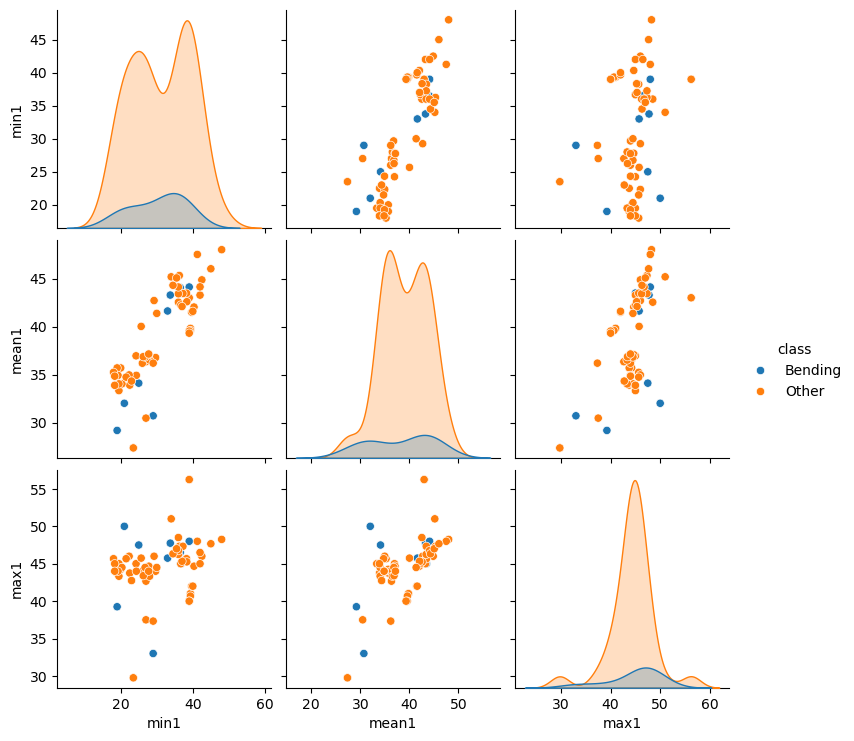

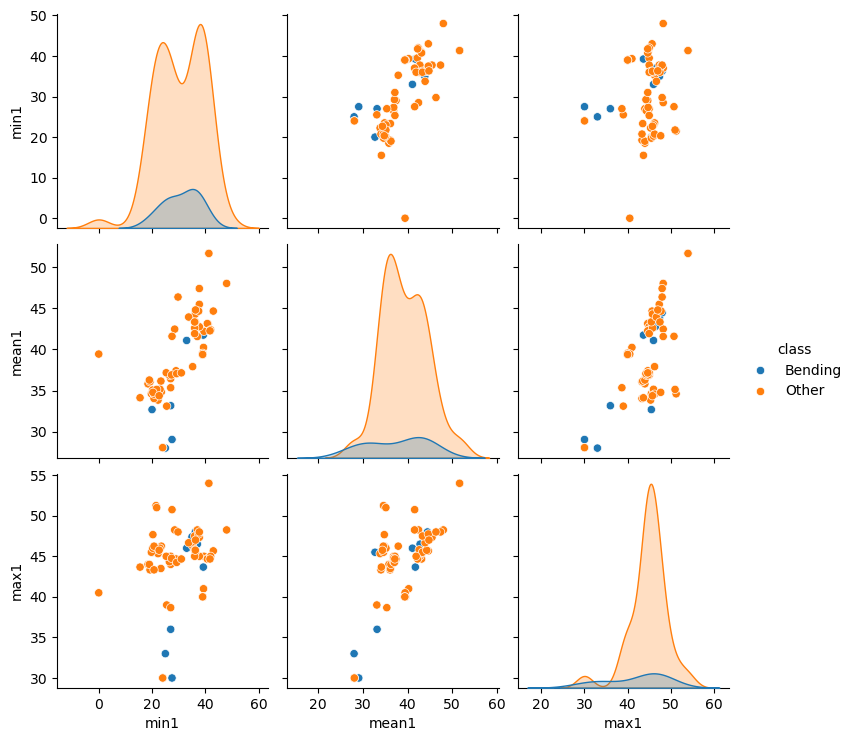

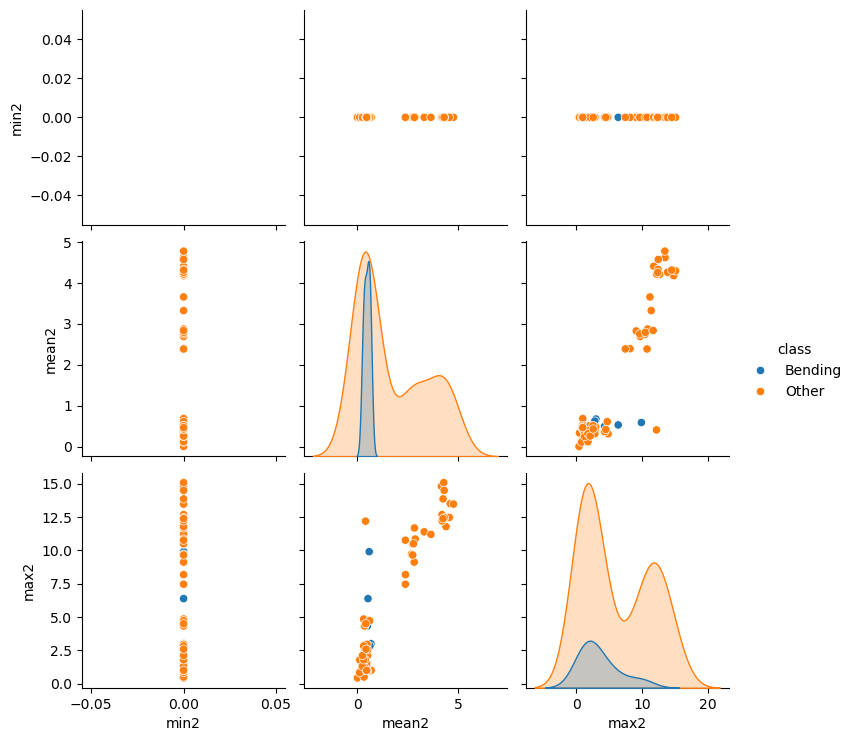

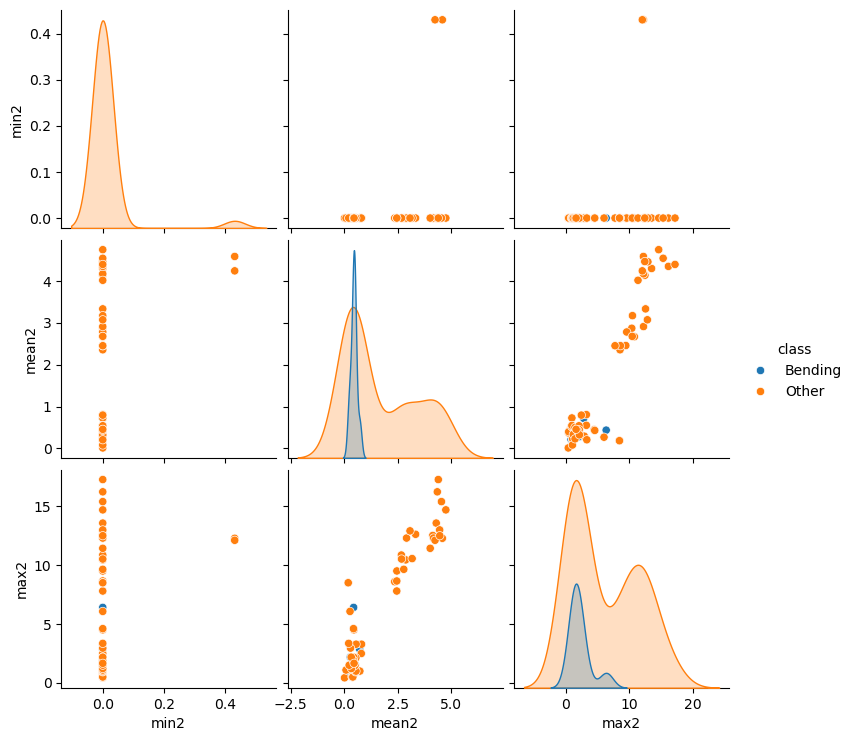

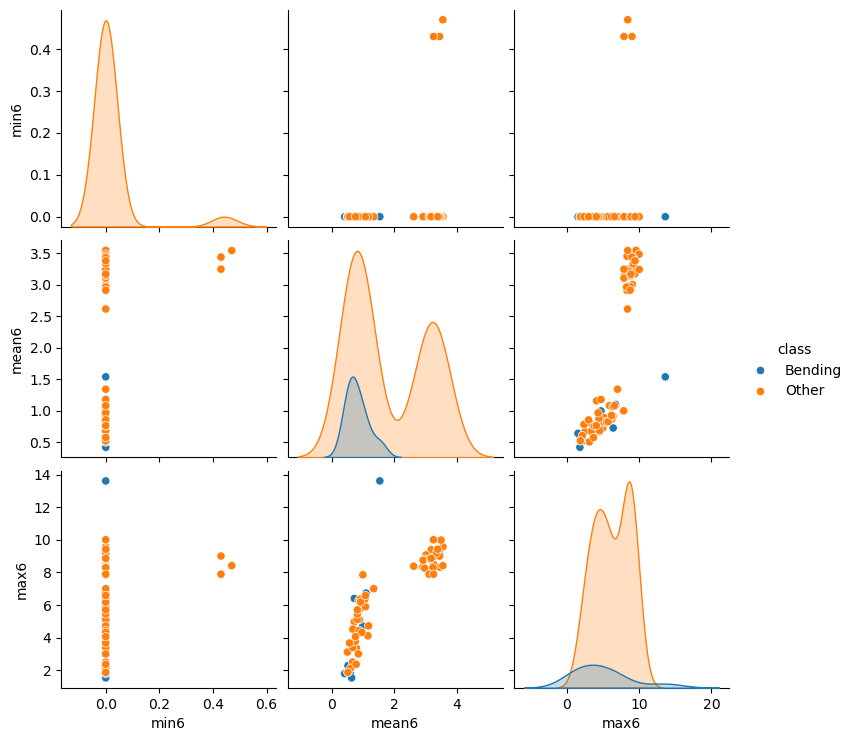

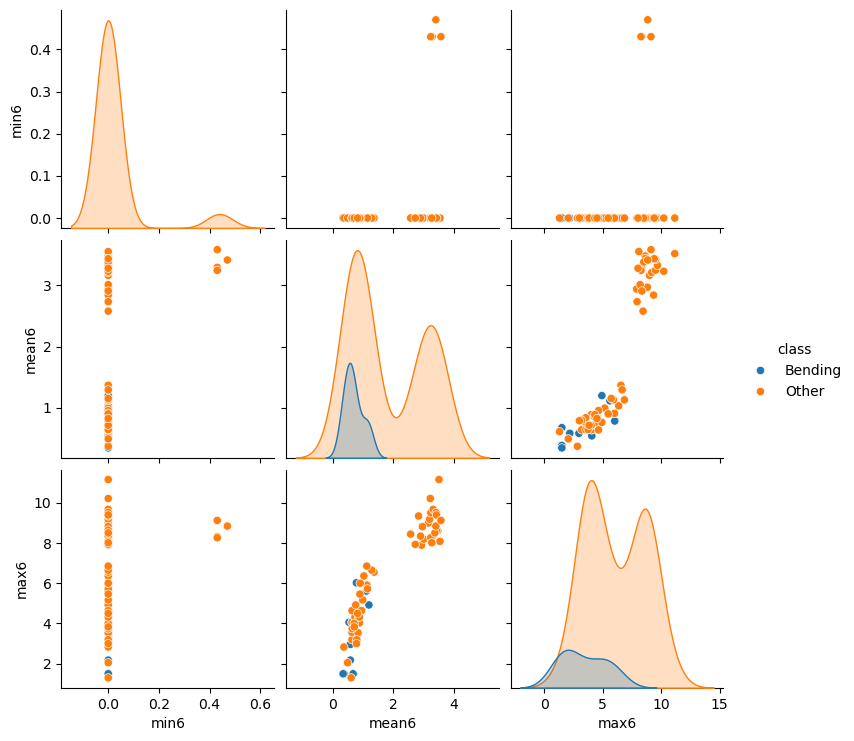

In [19]:
sensors = {1: "avg_rss12", 2: "var_rss12", 6: "var_rss23"}
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13",
           "var_rss13", "avg_rss23", "var_rss23"]
rows = []

for file in train_files:
    raw_rows = []
    with open(file) as f:
        for line in f.readlines()[5:]:
            values = line.replace(",", " ").split()
            if len(values) >= 7:
                raw_rows.append([float(x) for x in values[:7]])

    data = pd.DataFrame(raw_rows, columns=columns)
    label = "Bending" if Path(file).parent.name.startswith("bending") else "Other"

    mid = len(data) // 2
    for half_num, half in enumerate([data.iloc[:mid], data.iloc[mid:]], start=1):
        row = {"class": label, "half": half_num}
        for series, sensor in sensors.items():
            for stat in ["min", "mean", "max"]:
                row[f"{stat}{series}"] = getattr(half[sensor], stat)()
        rows.append(row)

half_df = pd.DataFrame(rows)

for series in [1, 2, 6]:
    for half_num in [1, 2]:
        sns.pairplot(
            half_df[half_df["half"] == half_num],
            vars=[f"min{series}", f"mean{series}", f"max{series}"],
            hue="class"
        )

Compared with the full-series plots, the half-series plots show some variation, but the overall patterns are similar and the Bending and Other classes still overlap substantially. Splitting the series into halves does not create a considerable improvement in visual separation.

#### iii. Time Series Segments

In [22]:
sensors = [
    "avg_rss12", "var_rss12", "avg_rss13",
    "var_rss13", "avg_rss23", "var_rss23"
]

stats = {
    "min": np.min,
    "max": np.max,
    "mean": np.mean,
    "median": np.median,
    "std": lambda x: np.std(x, ddof=1),
    "first_quartile": lambda x: np.percentile(x, 25),
    "third_quartile": lambda x: np.percentile(x, 75)
}

def make_features(l):
    rows = []

    for file in train_files:
        raw = []
        with open(file) as f:
            for line in f.readlines()[5:]:
                x = line.replace(",", " ").split()
                if len(x) >= 7:
                    raw.append([float(v) for v in x[:7]])

        data = pd.DataFrame(raw, columns=["time"] + sensors)
        row = {
            "file": str(Path(file).relative_to(Path(data_dir))),
            "activity": Path(file).parent.name
        }

        for sensor in sensors:
            segments = np.array_split(data[sensor].to_numpy(), l)
            for part, values in enumerate(segments, start=1):
                for name, fn in stats.items():
                    row[f"{sensor}_part{part}_{name}"] = fn(values)

        rows.append(row)

    return pd.DataFrame(rows)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
results = []

for l in range(1, 21):
    table = make_features(l)
    X = table.drop(columns=["file", "activity"])
    y = table["activity"].str.startswith("bending").astype(int)

    model = Pipeline([
        ("scale", StandardScaler()),
        ("logit", LogisticRegression(
            C=1e6, solver="liblinear", max_iter=1000
        ))
    ])

    selector = RFECV(
        model,
        step=0.5,
        cv=cv,
        scoring="accuracy",
        importance_getter="named_steps.logit.coef_"
    )
    selector.fit(X, y)

    results.append([
        l,
        selector.n_features_,
        selector.cv_results_["mean_test_score"].max()
    ])

results_df = pd.DataFrame(results, columns=["l", "p", "CV accuracy"])
results_df = results_df.sort_values("CV accuracy", ascending=False).reset_index(drop=True)
results_df.head()

,l,p,CV accuracy
0,3,1,0.985714
1,1,21,0.957143
2,2,1,0.928571
3,18,378,0.927473
4,4,84,0.913187


#### iv. Confusion Matrix

Best l: 3 | Best p: 1
Selected features: ['avg_rss23_part1_max']
Training confusion matrix:
 [[60  0]
 [ 1  8]]
Training AUC: 0.975


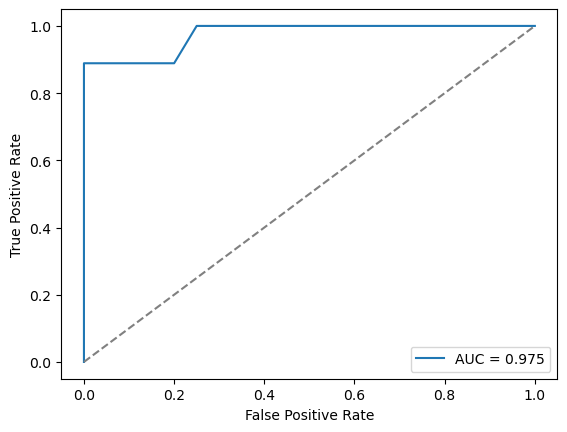

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               activity   No. Observations:                   69
Model:                          Logit   Df Residuals:                       67
Method:                           MLE   Df Model:                            1
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.7699
Time:                        20:14:22   Log-Likelihood:                -6.1467
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.416e-10
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 -21.8516      7.323     -2.984      0.003     -36.204      -7.499
avg_rss23_part1_max     0.7652      0.274      2.794      0.005       0.229       1.302
=======================================================================================

Possibly complete quasi-separation: A fraction 0.12 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

In [24]:
best_l = int(results_df.iloc[0]["l"])
best_p = int(results_df.iloc[0]["p"])

table = make_features(best_l)
X = table.drop(columns=["file", "activity"])
y = table["activity"].str.startswith("bending").astype(int)

model = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(
        C=1e6, solver="liblinear", max_iter=1000
    ))
])

selector = RFE(
    model, n_features_to_select=best_p, step=0.5,
    importance_getter="named_steps.logit.coef_"
).fit(X, y)

selected = X.columns[selector.support_]
X_selected = X[selected]

classifier = model.fit(X_selected, y)
predictions = classifier.predict(X_selected)
probabilities = classifier.predict_proba(X_selected)[:, 1]

print("Best l:", best_l, "| Best p:", best_p)
print("Selected features:", list(selected))
print("Training confusion matrix:\n", confusion_matrix(y, predictions))
print("Training AUC:", roc_auc_score(y, probabilities))

fpr, tpr, _ = roc_curve(y, probabilities)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y, probabilities):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Coefficients and p-values
statsmodels_fit = sm.Logit(y, sm.add_constant(X_selected)).fit(disp=False)
statsmodels_fit.summary()

#### v. Test Classifier

In [26]:
def make_features(l, files):
    rows = []

    for file in files:
        raw = []
        with open(file) as f:
            for line in f.readlines()[5:]:
                x = line.replace(",", " ").split()
                if len(x) >= 7:
                    raw.append([float(v) for v in x[:7]])

        data = pd.DataFrame(raw, columns=["time"] + sensors)
        row = {"activity": Path(file).parent.name}

        for sensor in sensors:
            for part, values in enumerate(np.array_split(data[sensor].to_numpy(), l), 1):
                for name, fn in stats.items():
                    row[f"{sensor}_part{part}_{name}"] = fn(values)

        rows.append(row)

    return pd.DataFrame(rows)

test_table = make_features(best_l, test_files)
X_test = test_table[selected]
y_test = test_table["activity"].str.startswith("bending").astype(int)
test_pred = classifier.predict(X_test)

print("Test confusion matrix:\n", confusion_matrix(y_test, test_pred))
print("Test accuracy:", accuracy_score(y_test, test_pred))
print("Best cross-validation accuracy:", results_df.iloc[0]["CV accuracy"])

Test confusion matrix:
 [[15  0]
 [ 2  2]]
Test accuracy: 0.8947368421052632
Best cross-validation accuracy: 0.9857142857142858


#### vi. Separation

The classes appear to be partially separated. The logistic regression output warned of possible quasi-separation, meaning the selected feature can perfectly predict some observations. This may make the estimated coefficients and p-values unstable. The training confusion matrix is not perfect overall, so the classes are not completely separated.

#### vii. Imbalance

Test confusion matrix:
 [[15  0]
 [ 2  2]]
Test AUC: 0.8500000000000001


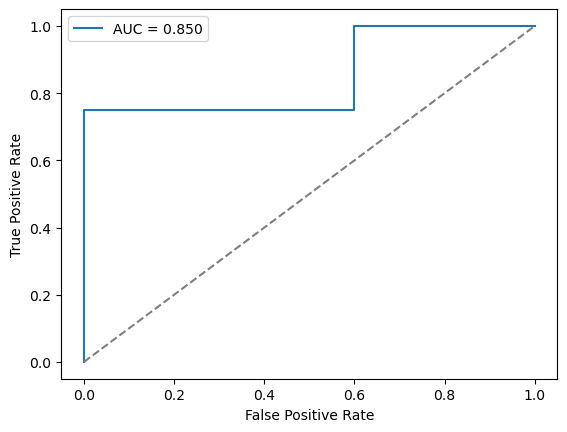

In [30]:
train_table = make_features(best_l, train_files)
test_table = make_features(best_l, test_files)

y_train = train_table["activity"].str.startswith("bending").astype(int)
y_test = test_table["activity"].str.startswith("bending").astype(int)

train = train_table[selected].copy()
train["y"] = y_train

other = train[train["y"] == 0]
bending = train[train["y"] == 1].sample(
    n=len(other), replace=True, random_state=1
)
balanced = pd.concat([other, bending])

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, solver="liblinear", max_iter=1000)
)
model.fit(balanced[selected], balanced["y"])

# Adjust the intercept for the original class proportion
lr = model.named_steps["logisticregression"]
lr.intercept_[0] += (
    np.log(y_train.mean() / (1 - y_train.mean()))
    - np.log(balanced["y"].mean() / (1 - balanced["y"].mean()))
)

prob = model.predict_proba(test_table[selected])[:, 1]
pred = (prob >= 0.5).astype(int)

print("Test confusion matrix:\n", confusion_matrix(y_test, pred))
print("Test AUC:", roc_auc_score(y_test, prob))

fpr, tpr, _ = roc_curve(y_test, prob)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, prob):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

After balancing the training data and adjusting the intercept, the model achieved a test AUC of 0.85. Its confusion matrix was the same as before, correctly classifying 15 Other files and 2 Bending files. In this test set, case-control sampling did not change the predictions at the 0.5 threshold.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
results = []
best_score = 0

for l in range(1, 21):
    data = make_features(l, train_files)
    X = data.drop(columns="activity")
    y = data["activity"].str.startswith("bending").astype(int)

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000)
    )
    search = GridSearchCV(
        model,
        {"logisticregression__C": np.logspace(-3, 3, 7)},
        cv=cv,
        scoring="accuracy"
    )
    search.fit(X, y)

    results.append([l, search.best_params_["logisticregression__C"],
                    search.best_score_])

    if search.best_score_ > best_score:
        best_score = search.best_score_
        best_l_l1 = l
        best_model_l1 = search.best_estimator_

results_df = pd.DataFrame(results, columns=["l", "C", "CV accuracy"])
print(results_df.sort_values("CV accuracy", ascending=False).head())
print("Best l:", best_l_l1)
print("Best CV accuracy:", best_score)
print("Number of selected features:",
      np.sum(best_model_l1.named_steps["logisticregression"].coef_[0] != 0))

     l      C  CV accuracy
0    1    1.0     0.970330
17  18    1.0     0.957143
12  13    1.0     0.957143
2    3    1.0     0.956044
9   10  100.0     0.942857
Best l: 1
Best CV accuracy: 0.9703296703296704
Number of selected features: 7


#### ii. Comparison

The variable-selection model from 2(a)(iii) performed slightly better, with 98.57% cross-validation accuracy compared with 97.03% for the L1-penalized model. L1 logistic regression was easier to implement because it selected features automatically by shrinking some coefficients to zero.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Best l: 2
Best CV accuracy: 0.857843137254902
Test error: 0.1578947368421053
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         1        0      0        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          1         0        0      0        1         1        0
standing         0         0        0      0        0         3        0
walking          0         0        0      0        0         0        3
Macro AUC: 0.9838935574229692


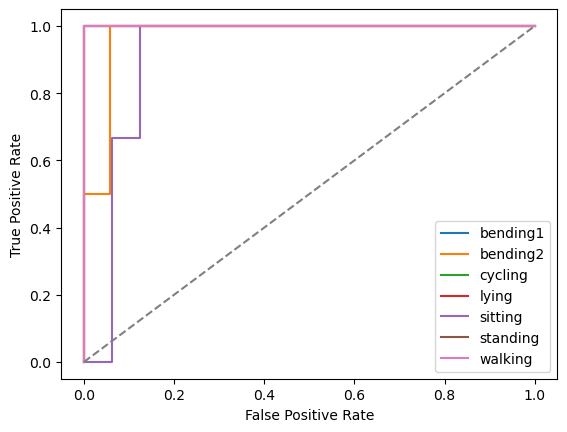

Best C: 100.0


In [39]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=1)
best_score = -1

for l in range(1, 21):
    data = make_features(l, train_files)
    X = data.drop(columns="activity")
    y = data["activity"]

    search = GridSearchCV(
        make_pipeline(
            StandardScaler(),
            LogisticRegression(penalty="l1", solver="saga",
                               max_iter=3000, tol=0.001)
        ),
        {"logisticregression__C": np.logspace(-2, 2, 5)},
        cv=cv
    )
    search.fit(X, y)

    if search.best_score_ > best_score:
        best_l, best_score = l, search.best_score_
        model = search.best_estimator_

test = make_features(best_l, test_files)
X_test = test.drop(columns="activity")
y_test = test["activity"]

pred = model.predict(X_test)
prob = model.predict_proba(X_test)
classes = model.classes_

print("Best l:", best_l)
print("Best CV accuracy:", best_score)
print("Test error:", 1 - accuracy_score(y_test, pred))
print(pd.DataFrame(confusion_matrix(y_test, pred, labels=classes),
                   index=classes, columns=classes))

y_bin = pd.get_dummies(y_test).reindex(columns=classes, fill_value=0).to_numpy()
print("Macro AUC:", roc_auc_score(y_bin, prob, average="macro"))

for i, name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], prob[:, i])
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("Best C:", model.named_steps["logisticregression"].C)

#### ii. Naive Bayes

In [41]:
train = make_features(best_l, train_files)
test = make_features(best_l, test_files)
X_train, y_train = train.drop(columns="activity"), train["activity"]
X_test, y_test = test.drop(columns="activity"), test["activity"]

for name, nb in [("Gaussian", GaussianNB()), ("Multinomial", MultinomialNB())]:
    nb.fit(X_train, y_train)
    pred = nb.predict(X_test)
    prob = nb.predict_proba(X_test)
    y_bin = pd.get_dummies(y_test).reindex(
        columns=nb.classes_, fill_value=0
    ).to_numpy()

    print(name, "test error:", 1 - accuracy_score(y_test, pred))
    print(pd.DataFrame(confusion_matrix(y_test, pred, labels=nb.classes_),
                       index=nb.classes_, columns=nb.classes_))
    print(name, "macro AUC:", roc_auc_score(y_bin, prob, average="macro"))

Gaussian test error: 0.368421052631579
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         0         0        0      2        0         0        0
bending2         0         0        0      1        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      1        1         1        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3
Gaussian macro AUC: 0.8461134453781513
Multinomial test error: 0.26315789473684215
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         2         0        0      0        0         0        0
cycling          0         0        3      0        0         0        0
ly

#### iii. Comparison

The L1-penalized logistic regression performed best overall, with the lowest test error (15.79%) and highest macro AUC (0.984). Multinomial Naive Bayes performed better than Gaussian Naive Bayes, but neither matched the logistic regression’s test accuracy.

## 3. ISLR 4.8.3

The Bayes classifier assigns an observation to the class with the highest posterior probability. For each class, this probability depends on the class’s prior probability and its normal density. Comparing two classes involves comparing their log probabilities. Because each class can have a different variance, the squared observation term does not cancel when the two classes are compared. Therefore, the decision boundary is generally quadratic rather than linear. If all classes had the same variance, the squared terms would cancel and the boundary would be linear.

## 4. ISLR 4.8.7

The prior probability of a company issuing a dividend is 0.80. At a profit of 4%, the normal density for companies that issued a dividend is about 1.32 times the density for companies that did not. Combining this likelihood ratio with the prior probability gives an estimated probability of approximately 0.841, or 84.1%, that the company will issue a dividend.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9